In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant # 상수항(intercept) 추가를 위함

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
df_total = pd.read_csv('/content/drive/MyDrive/Econometrics_Project_PNU/nba20232024_total.txt', delimiter = ',')
df_advanced = pd.read_csv('/content/drive/MyDrive/Econometrics_Project_PNU/nba20232024_advanced.txt', delimiter = ',')

In [5]:
Merged_df = pd.merge(df_total, df_advanced, on = 'Player')
Merged_df['FGF'] = Merged_df['FGA'] - Merged_df['FG']  ### FGF(야투 실패 개수) 변수 추가
len(Merged_df.columns)

63

In [6]:
print(Merged_df.columns)

Index(['Rk_x', 'Player', 'Age_x', 'Team_x', 'Pos_x', 'G_x', 'GS_x', 'MP_x',
       'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%',
       'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV',
       'PF', 'PTS', 'Trp-Dbl', 'Awards_x', 'Player-additional_x', 'Rk_y',
       'Age_y', 'Team_y', 'Pos_y', 'G_y', 'GS_y', 'MP_y', 'PER', 'TS%', '3PAr',
       'FTr', 'ORB%', 'DRB%', 'TRB%', 'AST%', 'STL%', 'BLK%', 'TOV%', 'USG%',
       'OWS', 'DWS', 'WS', 'WS/48', 'OBPM', 'DBPM', 'BPM', 'VORP', 'Awards_y',
       'Player-additional_y', 'FGF'],
      dtype='object')


In [7]:
columns_need = ['Player', 'G_x', 'PTS', 'TRB', 'AST', 'STL', 'BLK', 'FT%', 'TOV', 'FGF', 'PF', 'PER', 'Pos_x']

In [8]:
Merged_df = Merged_df[columns_need]

In [9]:
Merged_df

,Player,G_x,PTS,TRB,AST,STL,BLK,FT%,TOV,FGF,PF,PER,Pos_x
0,Luka Dončić,70,2370,647,686,99,38,0.786,282,848,149,28.1,PG
1,Shai Gilgeous-Alexander,75,2254,415,465,150,67,0.874,162,691,184,29.3,PG
2,Giannis Antetokounmpo,73,2222,841,476,87,79,0.657,250,532,210,29.9,PF
3,Jalen Brunson,77,2212,278,519,70,13,0.847,186,858,144,23.4,PG
4,Nikola Jokić,79,2085,976,708,108,68,0.817,237,589,194,31.0,C
...,...,...,...,...,...,...,...,...,...,...,...,...,...
567,Danny Green,2,0,2,1,1,0,NaN,0,2,1,0.7,SG
568,Ron Harper Jr.,1,0,0,1,0,0,NaN,0,0,2,0.0,PF
569,Justin Jackson,2,0,0,0,0,0,NaN,0,0,0,0.0,SF
570,Dmytro Skapintsev,2,0,0,0,0,0,NaN,0,1,0,-19.3,C


In [10]:
# 결측치(NaN), 0 있는 행렬 정리

##  결측치 (NaN)가 있는 행 제거(전체 열)
Merged_df = Merged_df.dropna()

## 0 있는 행 제거(G_x만 정리)
Merged_df = Merged_df[Merged_df['G_x'] != 0]

nba_data_df <----- 이거 기본 회귀에 들어가는 DataFrame

In [11]:
columns_original_need = ['Player', 'PER', 'PTS_g', 'TRB_g', 'AST_g', 'STL_g', 'BLK_g', 'FT%', 'TOV_g', 'FGF_g', 'PF_g', "Pos_x"]

In [12]:
nba_data_df = pd.DataFrame(columns = columns_original_need)
nba_data_df.columns

Index(['Player', 'PER', 'PTS_g', 'TRB_g', 'AST_g', 'STL_g', 'BLK_g', 'FT%',
       'TOV_g', 'FGF_g', 'PF_g', 'Pos_x'],
      dtype='object')

In [13]:
nba_data_df['Player'] = Merged_df['Player']
nba_data_df['PER'] = Merged_df['PER']
nba_data_df['Pos_x'] = Merged_df['Pos_x']
nba_data_df['PTS_g'] = Merged_df['PTS'] / Merged_df['G_x']
nba_data_df['TRB_g'] = Merged_df['TRB'] / Merged_df['G_x']
nba_data_df['AST_g'] = Merged_df['AST'] / Merged_df['G_x']
nba_data_df['STL_g'] = Merged_df['STL'] / Merged_df['G_x']
nba_data_df['BLK_g'] = Merged_df['BLK'] / Merged_df['G_x']
nba_data_df['FT%'] = Merged_df['FT%']
nba_data_df['TOV_g'] = Merged_df['TOV'] / Merged_df['G_x']
nba_data_df['FGF_g'] = Merged_df['FGF'] / Merged_df['G_x']
nba_data_df['PF_g'] = Merged_df['PF'] / Merged_df['G_x']

In [14]:
nba_data_df.head(5)

,Player,PER,PTS_g,TRB_g,AST_g,STL_g,BLK_g,FT%,TOV_g,FGF_g,PF_g,Pos_x
0,Luka Dončić,28.1,33.857143,9.242857,9.800000,1.414286,0.542857,0.786,4.028571,12.114286,2.128571,PG
1,Shai Gilgeous-Alexander,29.3,30.053333,5.533333,6.200000,2.000000,0.893333,0.874,2.160000,9.213333,2.453333,PG
2,Giannis Antetokounmpo,29.9,30.438356,11.520548,6.520548,1.191781,1.082192,0.657,3.424658,7.287671,2.876712,PF
3,Jalen Brunson,23.4,28.727273,3.610390,6.740260,0.909091,0.168831,0.847,2.415584,11.142857,1.870130,PG
4,Nikola Jokić,31.0,26.392405,12.354430,8.962025,1.367089,0.860759,0.817,3.000000,7.455696,2.455696,C


In [15]:
####### 원본데이터의 기술적 통계량
nba_data_df_describe = nba_data_df.drop(columns = ['FGF_g'])
nba_data_df_describe = nba_data_df_describe.head(300)
nba_data_df_describe.describe()

,PER,PTS_g,TRB_g,AST_g,STL_g,BLK_g,FT%,TOV_g,PF_g
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,15.048000,12.867313,4.657728,2.975382,0.804123,0.543300,0.779633,1.444288,1.963161
std,4.328481,6.374328,2.387919,1.990023,0.333661,0.462125,0.084507,0.783291,0.585321
min,7.700000,4.238806,0.833333,0.460000,0.190476,0.031250,0.440000,0.287879,0.727273
25%,11.900000,7.776364,3.034685,1.380373,0.557494,0.252799,0.731500,0.856673,1.500000
50%,14.400000,11.013932,4.075000,2.372088,0.775986,0.446581,0.791500,1.271058,1.928017
75%,17.625000,16.730640,5.529004,4.135704,0.985861,0.663731,0.836250,1.800893,2.344705
max,34.100000,34.692308,13.658537,10.898551,2.050000,3.577465,0.944000,4.351852,3.590909


In [16]:
### VIF 측정하기 위해 불필요한 변수 분리.
nba_data_df_1 = nba_data_df.drop(columns = ['Player','Pos_x'])
nba_data_df_2 = nba_data_df.drop(columns = ['Player', 'FGF_g','Pos_x']) # PTS_g, FGF_g 둘 사이 VIF가 너무 높아서 덜 중요한 FGF_g 죽이기

-------           TEST용 회귀분석          --------

In [17]:
import statsmodels.api as sm # 회귀 분석을 위한 라이브러리

In [18]:
nba_data_regression_test_df = nba_data_df_2.copy()

In [19]:
nba_data_regression_test_df.head(5)

,PER,PTS_g,TRB_g,AST_g,STL_g,BLK_g,FT%,TOV_g,PF_g
0,28.1,33.857143,9.242857,9.800000,1.414286,0.542857,0.786,4.028571,2.128571
1,29.3,30.053333,5.533333,6.200000,2.000000,0.893333,0.874,2.160000,2.453333
2,29.9,30.438356,11.520548,6.520548,1.191781,1.082192,0.657,3.424658,2.876712
3,23.4,28.727273,3.610390,6.740260,0.909091,0.168831,0.847,2.415584,1.870130
4,31.0,26.392405,12.354430,8.962025,1.367089,0.860759,0.817,3.000000,2.455696


In [20]:
nba_data_regression_test_df = nba_data_regression_test_df.head(300)
nba_data_regression_test_df.describe()

,PER,PTS_g,TRB_g,AST_g,STL_g,BLK_g,FT%,TOV_g,PF_g
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,15.048000,12.867313,4.657728,2.975382,0.804123,0.543300,0.779633,1.444288,1.963161
std,4.328481,6.374328,2.387919,1.990023,0.333661,0.462125,0.084507,0.783291,0.585321
min,7.700000,4.238806,0.833333,0.460000,0.190476,0.031250,0.440000,0.287879,0.727273
25%,11.900000,7.776364,3.034685,1.380373,0.557494,0.252799,0.731500,0.856673,1.500000
50%,14.400000,11.013932,4.075000,2.372088,0.775986,0.446581,0.791500,1.271058,1.928017
75%,17.625000,16.730640,5.529004,4.135704,0.985861,0.663731,0.836250,1.800893,2.344705
max,34.100000,34.692308,13.658537,10.898551,2.050000,3.577465,0.944000,4.351852,3.590909


In [21]:
nba_data_regression_test_df.head(5)

,PER,PTS_g,TRB_g,AST_g,STL_g,BLK_g,FT%,TOV_g,PF_g
0,28.1,33.857143,9.242857,9.800000,1.414286,0.542857,0.786,4.028571,2.128571
1,29.3,30.053333,5.533333,6.200000,2.000000,0.893333,0.874,2.160000,2.453333
2,29.9,30.438356,11.520548,6.520548,1.191781,1.082192,0.657,3.424658,2.876712
3,23.4,28.727273,3.610390,6.740260,0.909091,0.168831,0.847,2.415584,1.870130
4,31.0,26.392405,12.354430,8.962025,1.367089,0.860759,0.817,3.000000,2.455696


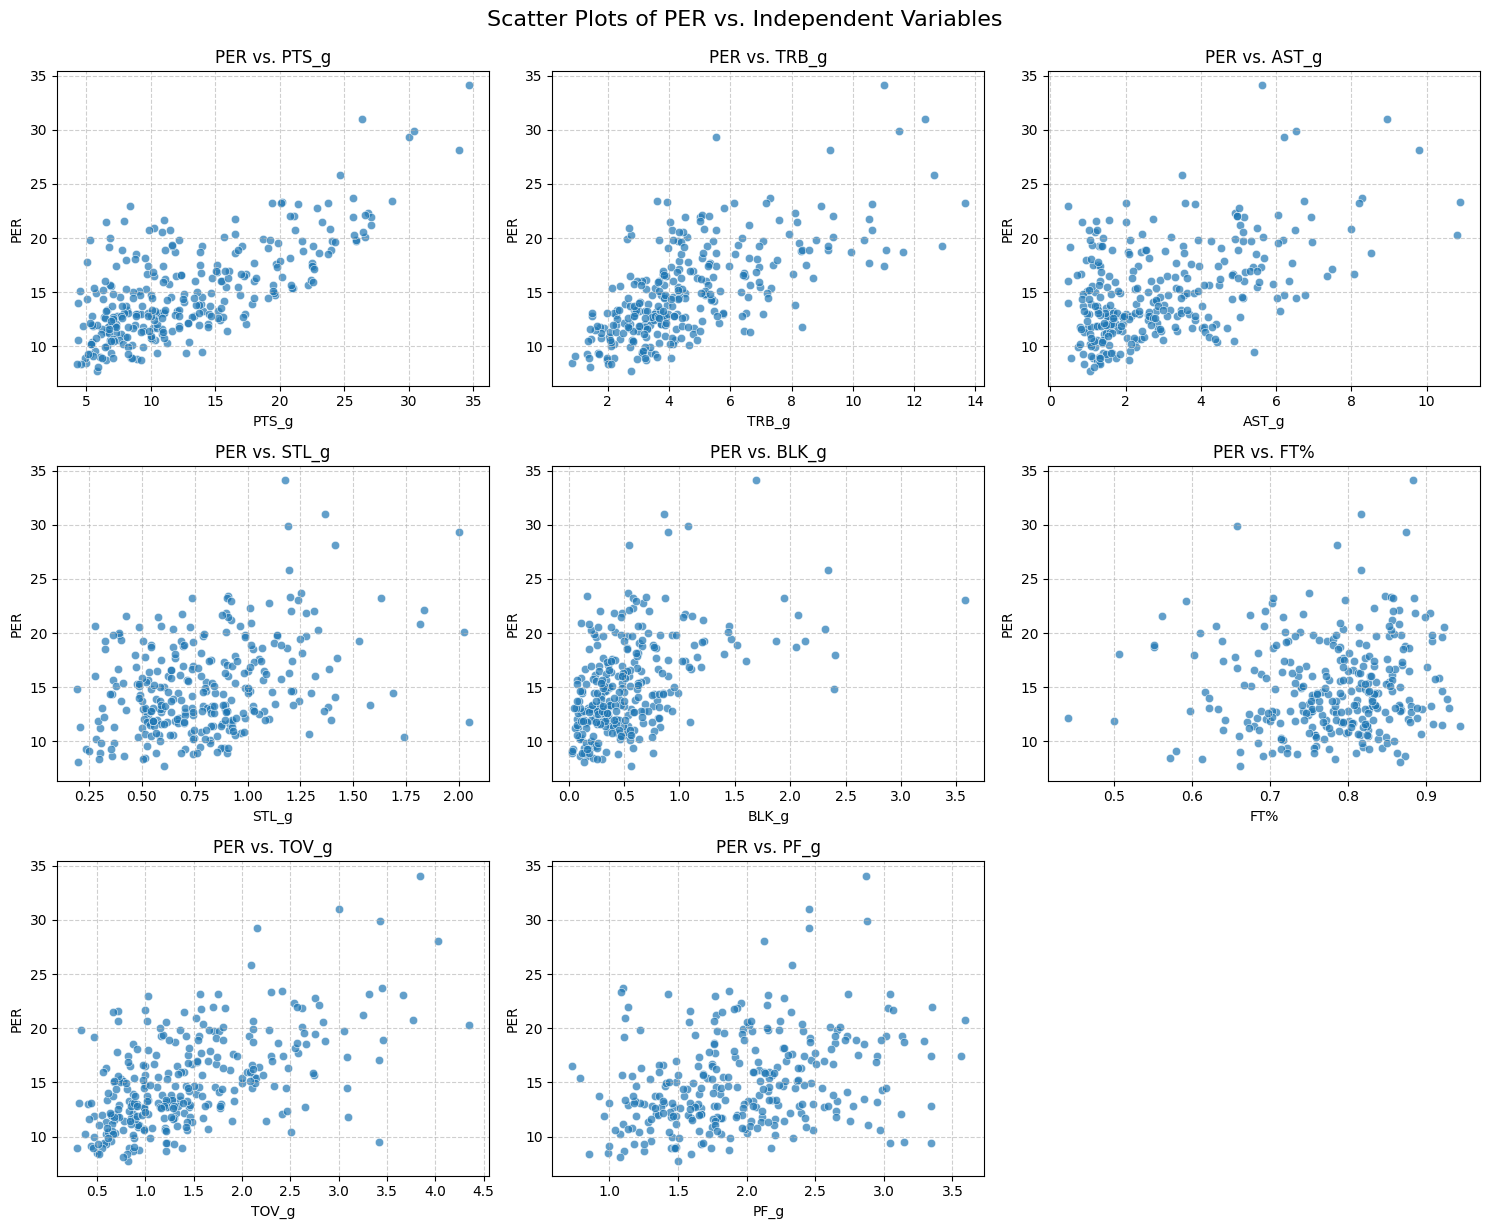

In [22]:

# 산포도를 그릴 독립변수 리스트
independent_variables = ['PTS_g', 'TRB_g', 'AST_g', 'STL_g', 'BLK_g', 'FT%','TOV_g', 'PF_g']
dependent_variable = 'PER'

# 서브플롯 설정을 위한 행과 열 계산 (8개 그래프에 적합하도록 조정 가능)
# 7개 독립변수 + 1 (PER vs PER은 의미 없으므로) => 7개 산포도.
# 보통 2x4 또는 3x3 배열로 그립니다. 여기서는 3x3 배열로 하겠습니다.
n_cols = 3
n_rows = (len(independent_variables) + n_cols - 1) // n_cols # 올림 계산

plt.figure(figsize=(n_cols * 5, n_rows * 4)) # 전체 그림 크기 조정

for i, col in enumerate(independent_variables):
    plt.subplot(n_rows, n_cols, i + 1) # i+1은 현재 서브플롯 인덱스
    sns.scatterplot(x=col, y=dependent_variable, data=nba_data_regression_test_df, alpha=0.7)
    plt.title(f'{dependent_variable} vs. {col}')
    plt.xlabel(col)
    plt.ylabel(dependent_variable)
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout() # 서브플롯들이 겹치지 않도록 자동 조정
plt.suptitle(f'Scatter Plots of {dependent_variable} vs. Independent Variables', y=1.02, fontsize=16) # 전체 제목
plt.show()

# # ----------------------------------------------------------------------------
# # 선택적: 로그 변환된 변수들의 산포도도 보고 싶다면 (비선형성 확인)
# # image_c37d81.png에서 로그 변환된 스탯을 볼 수 있습니다.
# print("\n--- 로그 변환된 변수들의 산포도 (선택 사항) ---")
# # 가상으로 로그 변환 컬럼 추가
# for col in independent_variables:
#     nba_data_regression_test_df[f'log_{col}'] = np.log1p(nba_data_regression_test_df[col]) # 0 값이 있을 수 있으므로 log1p 사용
# nba_data_regression_test_df[f'log_{dependent_variable}'] = np.log1p(nba_data_regression_test_df[dependent_variable])

# log_independent_variables = [f'log_{col}' for col in independent_variables]
# log_dependent_variable = f'log_{dependent_variable}'

# plt.figure(figsize=(n_cols * 5, n_rows * 4))

# for i, col in enumerate(log_independent_variables):
#     plt.subplot(n_rows, n_cols, i + 1)
#     sns.scatterplot(x=col, y=log_dependent_variable, data=nba_data_regression_test_df, alpha=0.7)
#     plt.title(f'{log_dependent_variable} vs. {col}')
#     plt.xlabel(col)
#     plt.ylabel(log_dependent_variable)
#     plt.grid(True, linestyle='--', alpha=0.6)

# plt.tight_layout()
# plt.suptitle(f'Scatter Plots of Log-transformed {dependent_variable} vs. Log-transformed Independent Variables', y=1.02, fontsize=16)
# plt.show()

In [23]:
nba_data_regression_test_df = nba_data_regression_test_df.head(300)
y_linear1 = nba_data_regression_test_df['PER']
X_linear1 = nba_data_regression_test_df.drop(columns = ['PER'])
X_linear1 = sm.add_constant(X_linear1)

model_linear1 = sm.OLS(y_linear1, X_linear1)
results_linear1 = model_linear1.fit()
print("------ 회귀 분석 결과 요약------")
print(results_linear1.summary())

------ 회귀 분석 결과 요약------
                            OLS Regression Results                            
Dep. Variable:                    PER   R-squared:                       0.726
Model:                            OLS   Adj. R-squared:                  0.718
Method:                 Least Squares   F-statistic:                     96.39
Date:                Thu, 26 Jun 2025   Prob (F-statistic):           3.17e-77
Time:                        06:40:46   Log-Likelihood:                -670.54
No. Observations:                 300   AIC:                             1359.
Df Residuals:                     291   BIC:                             1392.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          9.4639      

In [24]:
### t값 그리고 회귀계수가 유의해 보이지 않는 STL, FT% 제외한 모형. ---->  nba_data_regression_test_df_head_300
nba_data_regression_test_df_head_300 = nba_data_regression_test_df.head(300)
nba_data_regression_test_df_head_300 = nba_data_regression_test_df_head_300.drop(columns = ['STL_g', 'FT%'])
y_linear2 = nba_data_regression_test_df_head_300['PER']
X_linear2 = nba_data_regression_test_df_head_300.drop(columns = ['PER'])
X_linear2 = sm.add_constant(X_linear2)

model_linear2 = sm.OLS(y_linear2, X_linear2)
results_linear2 = model_linear2.fit()
print("------ 회귀 분석 결과 요약------")
print(results_linear2.summary())

------ 회귀 분석 결과 요약------
                            OLS Regression Results                            
Dep. Variable:                    PER   R-squared:                       0.724
Model:                            OLS   Adj. R-squared:                  0.719
Method:                 Least Squares   F-statistic:                     128.4
Date:                Thu, 26 Jun 2025   Prob (F-statistic):           5.53e-79
Time:                        06:40:46   Log-Likelihood:                -671.38
No. Observations:                 300   AIC:                             1357.
Df Residuals:                     293   BIC:                             1383.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.6066      

------ 회귀방정식 변수들의 분포를 확인하기 위한 작업 ------

In [25]:
# 분포를 시각화할 컬럼 목록 (종속변수 포함)
columns_to_plot = ['PER', 'PTS_g', 'TRB_g', 'AST_g', 'BLK_g', 'TOV_g', 'PF_g']

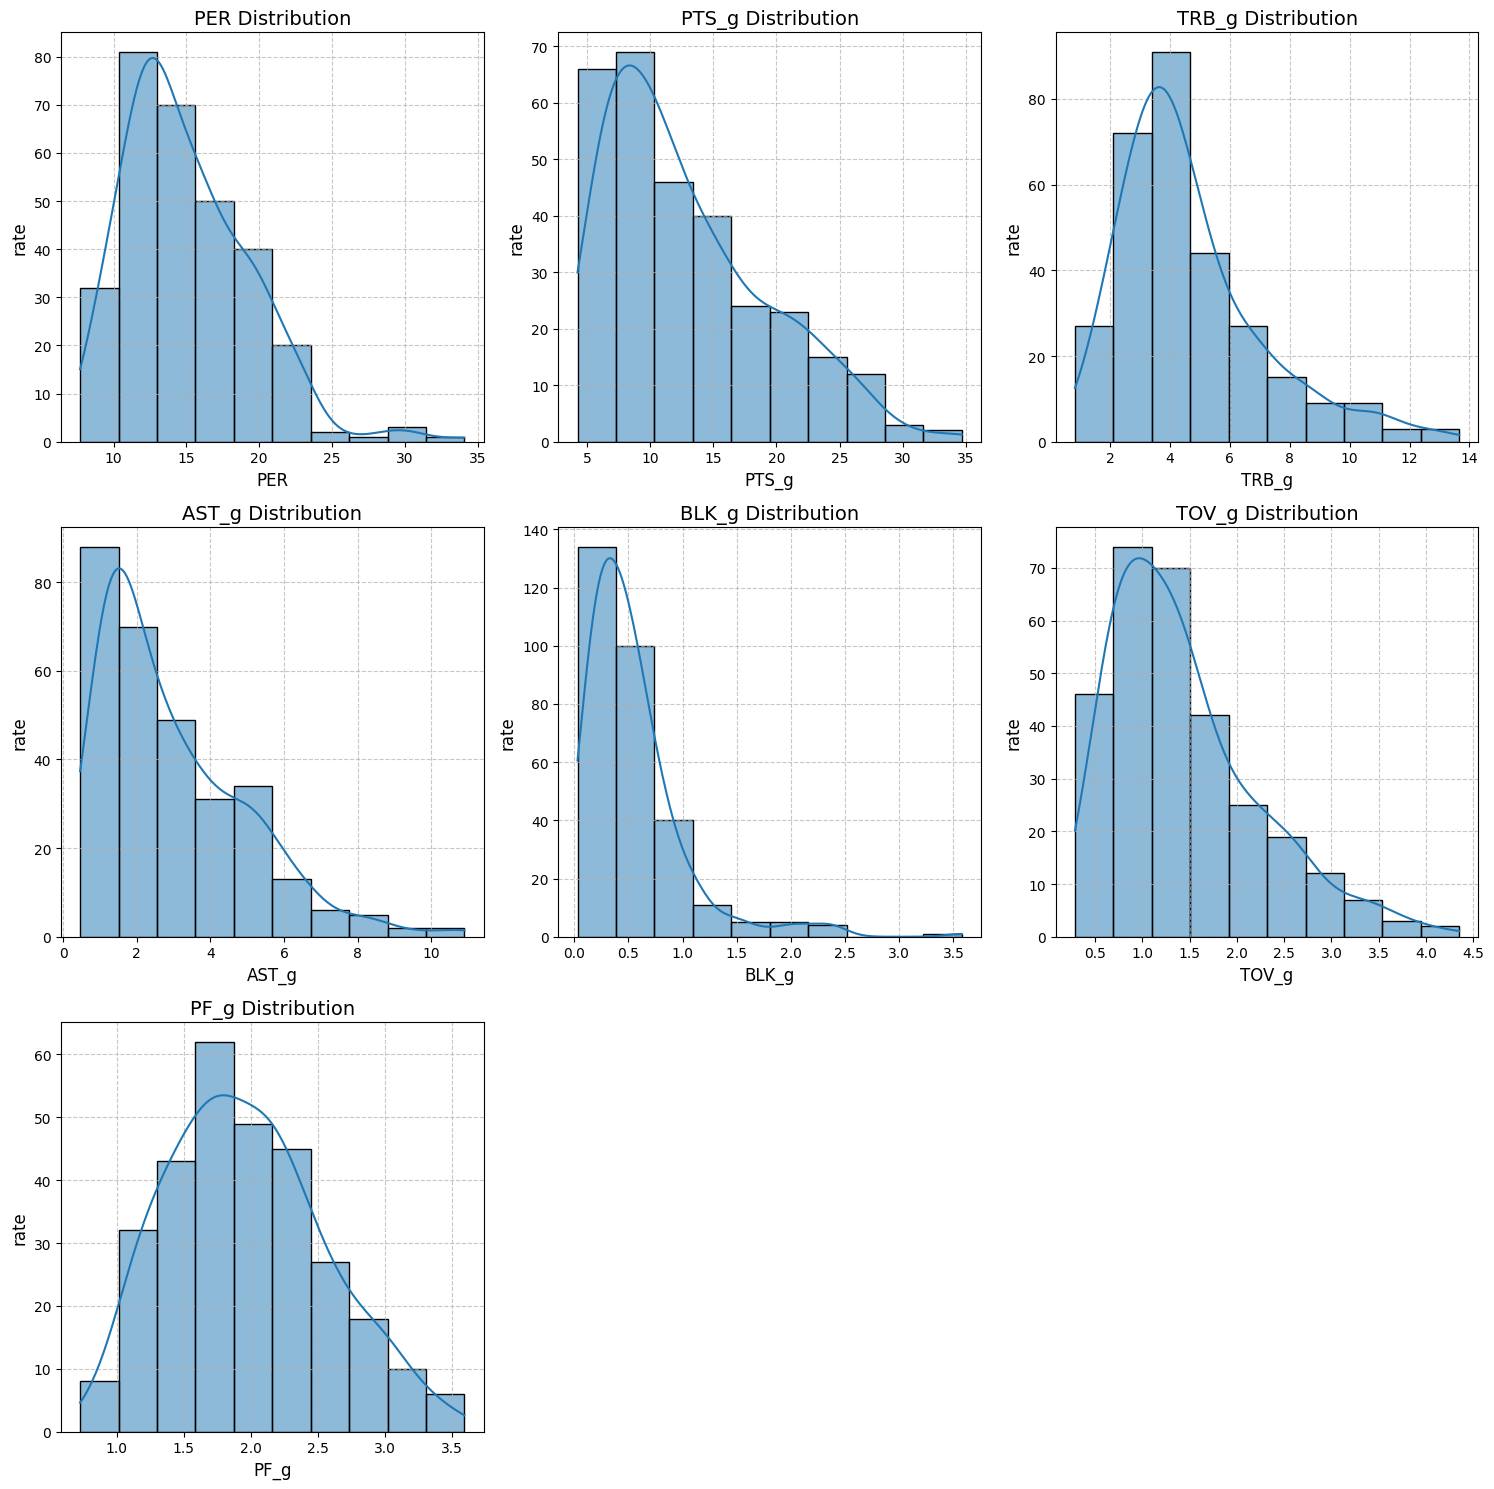

In [26]:
# 그래프의 전체 크기 및 레이아웃 설정
# (컬럼 개수에 따라 figsize와 subplots 그리드를 조절하세요)
num_cols = len(columns_to_plot)
num_rows = (num_cols + 2) // 3 # 한 줄에 3개씩 그릴 경우 (올림)
plt.figure(figsize=(15, 5 * num_rows))

for i, col in enumerate(columns_to_plot):
    plt.subplot(num_rows, 3, i + 1) # (행 개수, 열 개수, 현재 플롯 번호)
    sns.histplot(nba_data_regression_test_df_head_300[col], kde=True, bins=10) # bins는 막대 개수 조절
    plt.title(f'{col} Distribution', fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel('rate', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7) # 그리드 추가

plt.tight_layout() # 서브플롯 간의 간격을 자동으로 조정
plt.show()

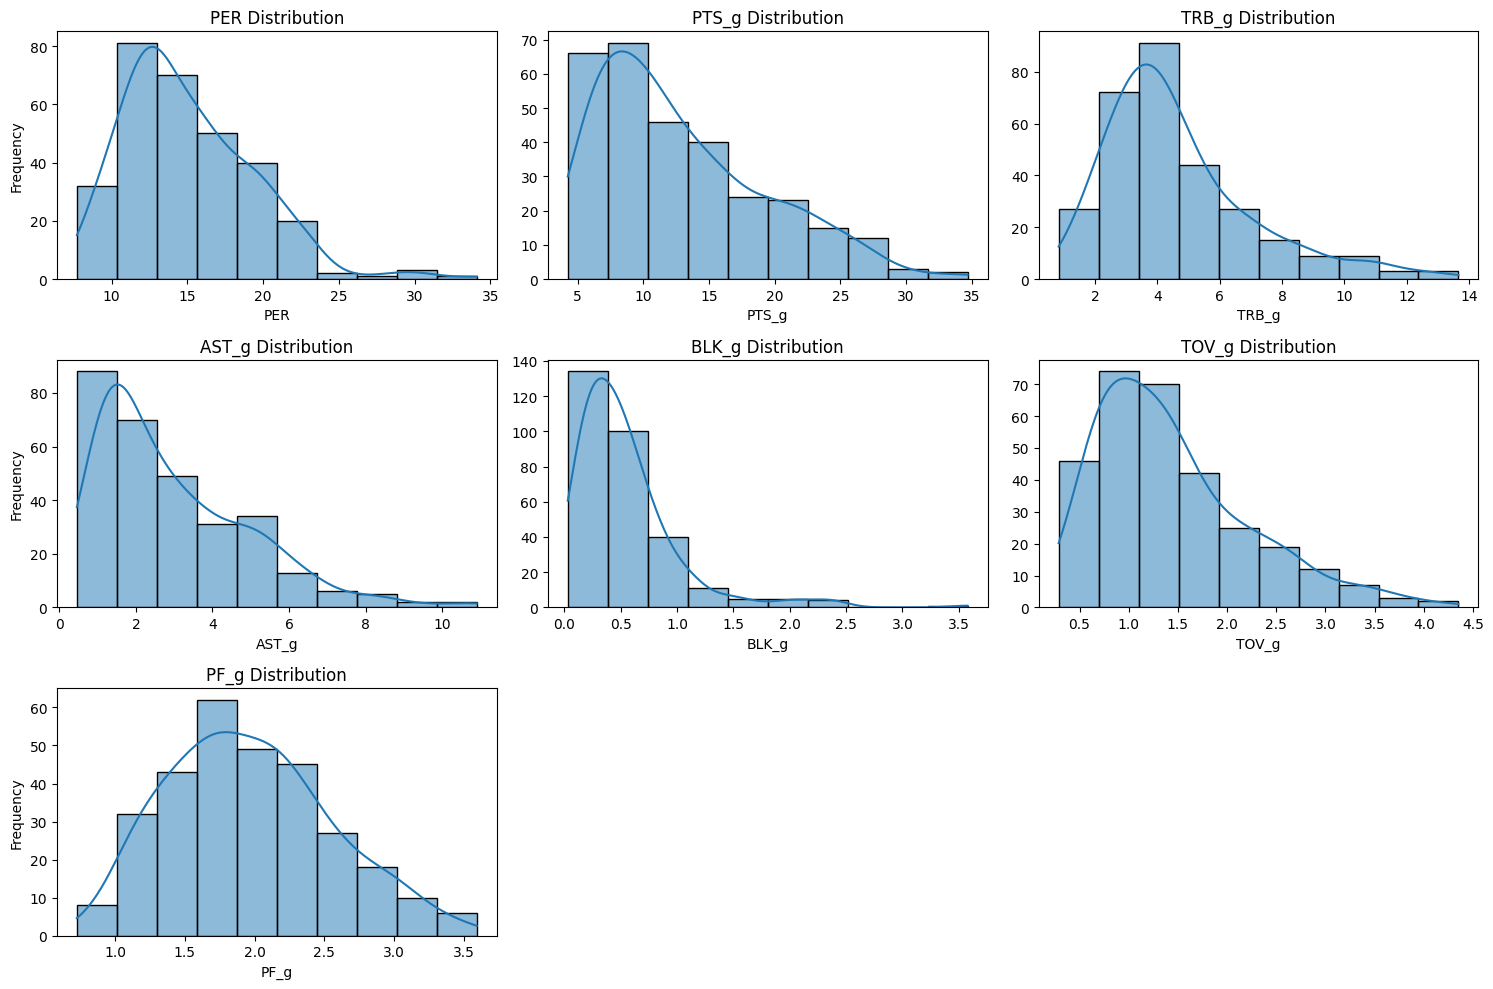

In [27]:
df_head_300 = nba_data_regression_test_df_head_300.copy()

columns_to_plot = ['PER', 'PTS_g', 'TRB_g', 'AST_g', 'BLK_g', 'TOV_g', 'PF_g']

# 각 변수의 분포를 개별적으로 그립니다.
plt.figure(figsize=(15, 10)) # 전체 그림의 크기 설정

for i, col in enumerate(columns_to_plot):
    plt.subplot(3, 3, i + 1) # 3행 3열의 서브플롯을 만들고, 현재 그릴 위치를 지정
    sns.histplot(df_head_300[col], kde=True, bins=10) # 히스토그램과 KDE 플롯을 함께 그림
    plt.title(f'{col} Distribution') # 각 서브플롯의 제목
    plt.xlabel(col) # x축 라벨
    plt.ylabel('Frequency' if i % 3 == 0 else '') # 왼쪽 열에만 y축 라벨 표시

plt.tight_layout() # 서브플롯 간의 간격을 자동으로 조절
plt.show() # 그래프 출력

------ 로그 변환 후 회귀 -------

독립변수 로그 변환 시작...
  - 'PTS_g' 변환 완료 -> 'log_PTS_g' 생성
  - 'TRB_g' 변환 완료 -> 'log_TRB_g' 생성
  - 'AST_g' 변환 완료 -> 'log_AST_g' 생성
  - 'BLK_g' 변환 완료 -> 'log_BLK_g' 생성
  - 'TOV_g' 변환 완료 -> 'log_TOV_g' 생성
  - 'PF_g' 변환 완료 -> 'log_PF_g' 생성

로그 변환 후 DataFrame의 상위 5행:
    PER      PTS_g      TRB_g     AST_g     BLK_g     TOV_g      PF_g  \
0  28.1  33.857143   9.242857  9.800000  0.542857  4.028571  2.128571   
1  29.3  30.053333   5.533333  6.200000  0.893333  2.160000  2.453333   
2  29.9  30.438356  11.520548  6.520548  1.082192  3.424658  2.876712   
3  23.4  28.727273   3.610390  6.740260  0.168831  2.415584  1.870130   
4  31.0  26.392405  12.354430  8.962025  0.860759  3.000000  2.455696   

   log_PTS_g  log_TRB_g  log_AST_g  log_BLK_g  log_TOV_g  log_PF_g  
0   3.551258   2.326581   2.379546   0.433636   1.615136  1.140576  
1   3.435706   1.876917   1.974081   0.638339   1.150572  1.239340  
2   3.448029   2.527371   2.017639   0.733421   1.487193  1.354987  
3   3.392065   1.528312   2

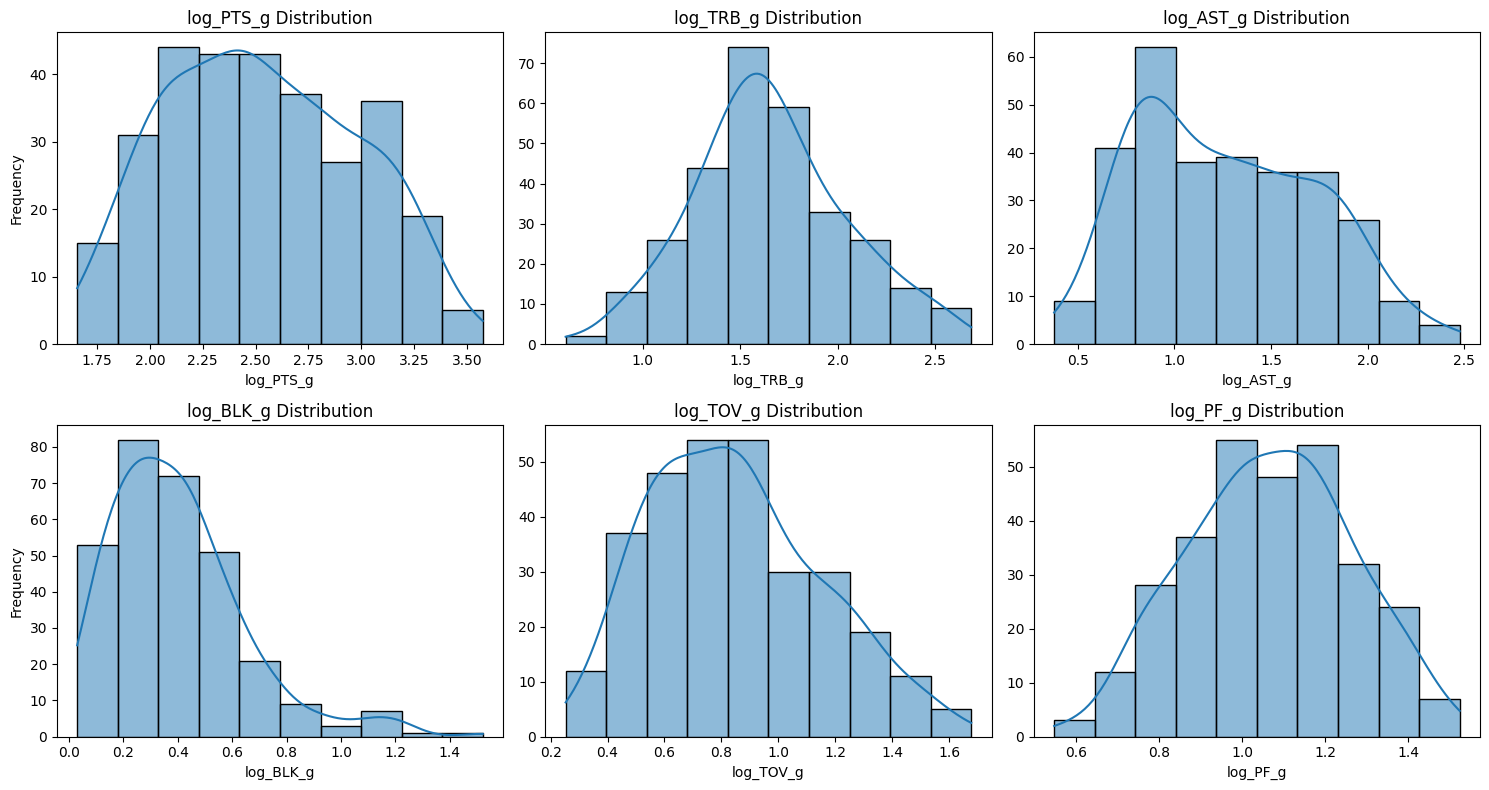


이제 'PER'을 종속변수로, 'log_PTS_g', 'log_TRB_g' 등 로그 변환된 변수들을 독립변수로 사용하여 선형 회귀 모델을 구축할 준비가 되었습니다.


In [28]:
df = nba_data_regression_test_df_head_300.copy()

# 종속변수와 독립변수 목록 정의
dependent_variable = 'PER'
independent_variables = ['PTS_g', 'TRB_g', 'AST_g', 'BLK_g', 'TOV_g', 'PF_g']

# 독립변수들에 로그 변환 적용
print("독립변수 로그 변환 시작...")
for col in independent_variables:
    # 새로운 컬럼 이름은 'log_' 접두사를 사용합니다.
    df[f'log_{col}'] = np.log1p(df[col])
    print(f"  - '{col}' 변환 완료 -> 'log_{col}' 생성")

print("\n로그 변환 후 DataFrame의 상위 5행:")
print(df.head())

print("\n-------------------------------------------")
print("로그 변환된 독립변수들의 분포를 시각화합니다.")

# 로그 변환된 독립변수들만 선택하여 분포 시각화
log_independent_columns = [f'log_{col}' for col in independent_variables]

plt.figure(figsize=(15, 8)) # 전체 그림의 크기 설정 (독립변수 수에 맞게 조절)

# 서브플롯 개수를 동적으로 설정 (예: 2행 n열 또는 3행 n열)
num_cols_to_plot = len(log_independent_columns)
rows = (num_cols_to_plot + 2) // 3 # 3개씩 나열했을 때 필요한 행 수
cols = 3 # 한 행에 3개의 그래프

for i, col in enumerate(log_independent_columns):
    plt.subplot(rows, cols, i + 1)
    sns.histplot(df[col], kde=True, bins=10)
    plt.title(f'{col} Distribution')
    plt.xlabel(col)
    plt.ylabel('Frequency' if i % cols == 0 else '') # 각 행의 첫 번째 그래프에만 y축 라벨 표시

plt.tight_layout()
plt.show()

print("\n이제 'PER'을 종속변수로, 'log_PTS_g', 'log_TRB_g' 등 로그 변환된 변수들을 독립변수로 사용하여 선형 회귀 모델을 구축할 준비가 되었습니다.")

In [29]:
log_columns = ['log_PTS_g', 'log_TRB_g', 'log_AST_g', 'log_BLK_g', 'log_TOV_g', 'log_PF_g']
df_log = df[log_columns]
df_log['PER'] = df['PER']

/tmp/ipython-input-29-1489176562.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_log['PER'] = df['PER']


In [30]:
### 여기서 PER은 ln(1+x) 변환이 아닌 ln(x)로 변환.
min_per_value = df['PER'].min()
print(f"PER 컬럼의 최소값: {min_per_value}")

# PER 컬럼에 0 이하의 값이 있는지 확인
if (df['PER'] <= 0).any():
    print("경고: PER 컬럼에 0 이하의 값이 존재합니다. log(x) 변환 시 오류가 발생할 수 있습니다.")
    print("  0 이하의 값 개수:", (df['PER'] <= 0).sum())
else:
    print("PER 컬럼에는 0 이하의 값이 없습니다. log(x) 변환을 안전하게 적용할 수 있습니다.")

PER 컬럼의 최소값: 7.7
PER 컬럼에는 0 이하의 값이 없습니다. log(x) 변환을 안전하게 적용할 수 있습니다.


In [31]:
dependent_variable = 'PER'
df_log[f'log_{dependent_variable}'] = np.log(df[dependent_variable])
print(f"'{dependent_variable}' 컬럼에 log(x) 변환 완료 -> 'log_{dependent_variable}' 생성")

'PER' 컬럼에 log(x) 변환 완료 -> 'log_PER' 생성


/tmp/ipython-input-31-2045224813.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_log[f'log_{dependent_variable}'] = np.log(df[dependent_variable])


In [32]:
df.head(5)

,PER,PTS_g,TRB_g,AST_g,BLK_g,TOV_g,PF_g,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g
0,28.1,33.857143,9.242857,9.800000,0.542857,4.028571,2.128571,3.551258,2.326581,2.379546,0.433636,1.615136,1.140576
1,29.3,30.053333,5.533333,6.200000,0.893333,2.160000,2.453333,3.435706,1.876917,1.974081,0.638339,1.150572,1.239340
2,29.9,30.438356,11.520548,6.520548,1.082192,3.424658,2.876712,3.448029,2.527371,2.017639,0.733421,1.487193,1.354987
3,23.4,28.727273,3.610390,6.740260,0.168831,2.415584,1.870130,3.392065,1.528312,2.046435,0.156004,1.228349,1.054357
4,31.0,26.392405,12.354430,8.962025,0.860759,3.000000,2.455696,3.310266,2.591848,2.298780,0.620985,1.386294,1.240024


In [33]:
df_log.head(5)

,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g,PER,log_PER
0,3.551258,2.326581,2.379546,0.433636,1.615136,1.140576,28.1,3.335770
1,3.435706,1.876917,1.974081,0.638339,1.150572,1.239340,29.3,3.377588
2,3.448029,2.527371,2.017639,0.733421,1.487193,1.354987,29.9,3.397858
3,3.392065,1.528312,2.046435,0.156004,1.228349,1.054357,23.4,3.152736
4,3.310266,2.591848,2.298780,0.620985,1.386294,1.240024,31.0,3.433987


In [34]:
df_log.columns

Index(['log_PTS_g', 'log_TRB_g', 'log_AST_g', 'log_BLK_g', 'log_TOV_g',
       'log_PF_g', 'PER', 'log_PER'],
      dtype='object')

In [35]:
### nba_data_regression_test_df_head_300 여기서 로그 변환 -------> df_log
y_log_non = df_log['PER']
X_log = df_log.drop(columns = ['PER','log_PER'])
X_log  = sm.add_constant(X_log)

model_log1 = sm.OLS(y_log_non, X_log)
results1 = model_log1.fit()
print("------ 회귀 분석 결과 요약------")
print(results1.summary())

------ 회귀 분석 결과 요약------
                            OLS Regression Results                            
Dep. Variable:                    PER   R-squared:                       0.656
Model:                            OLS   Adj. R-squared:                  0.649
Method:                 Least Squares   F-statistic:                     93.05
Date:                Thu, 26 Jun 2025   Prob (F-statistic):           6.54e-65
Time:                        06:40:52   Log-Likelihood:                -704.76
No. Observations:                 300   AIC:                             1424.
Df Residuals:                     293   BIC:                             1449.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.4384      

In [36]:
### nba_data_regression_test_df_head_300 여기서 로그 변환 -------> df_log
y_log = df_log['log_PER']
X_log = df_log.drop(columns = ['PER', 'log_PER'])
X_log  = sm.add_constant(X_log)

model_log2 = sm.OLS(y_log, X_log)
results2 = model_log2.fit()
print("------ 회귀 분석 결과 요약------")
print(results2.summary())

------ 회귀 분석 결과 요약------
                            OLS Regression Results                            
Dep. Variable:                log_PER   R-squared:                       0.664
Model:                            OLS   Adj. R-squared:                  0.657
Method:                 Least Squares   F-statistic:                     96.43
Date:                Thu, 26 Jun 2025   Prob (F-statistic):           2.13e-66
Time:                        06:40:52   Log-Likelihood:                 124.52
No. Observations:                 300   AIC:                            -235.0
Df Residuals:                     293   BIC:                            -209.1
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.5750      

------ 모델의 잔차 플롯 그려보기 ------

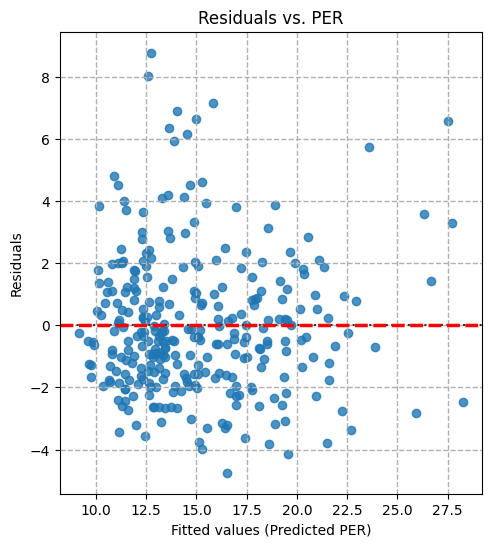

In [37]:
### 처음의 다중 선형 모델의 잔차 플롯
#model_linear2 = sm.OLS(y_linear2, X_linear2)
#results_linear2 = model_linear2.fit()

plt.figure(figsize=(12, 6))

# 1. 잔차 대 적합값 플롯 (Residuals vs. Fitted)
plt.subplot(1, 2, 1) # 1행 2열 중 첫 번째 플롯
sns.residplot(x=results_linear2.fittedvalues,
              y=results_linear2.resid)

plt.xlabel("Fitted values (Predicted PER)")
plt.ylabel("Residuals")
plt.title("Residuals vs. PER")
plt.grid(True, linestyle='--', alpha=1, linewidth = 1)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2.5) # linewidth로 두께 조절

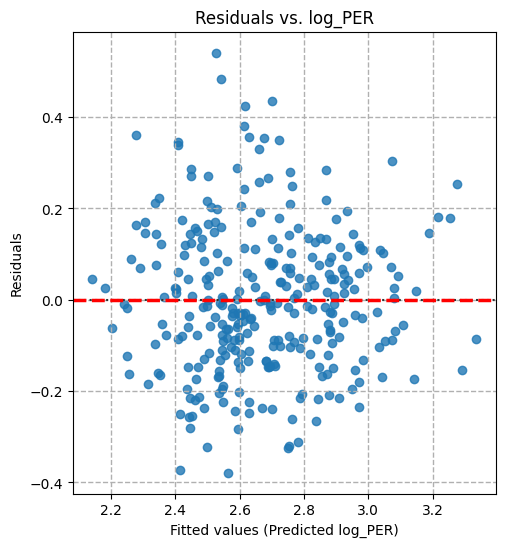

In [38]:
### 로그 변형 모델의 잔차플롯


plt.figure(figsize=(12, 6))

# 1. 잔차 대 적합값 플롯 (Residuals vs. Fitted)
plt.subplot(1, 2, 1) # 1행 2열 중 첫 번째 플롯
sns.residplot(x=results2.fittedvalues,
              y=results2.resid)

plt.xlabel("Fitted values (Predicted log_PER)")
plt.ylabel("Residuals")
plt.title("Residuals vs. log_PER")
plt.grid(True, linestyle='--', alpha=1, linewidth = 1)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2.5) # linewidth로 두께 조절


------ 회귀모형 변수들간의 상관계수 -------

In [39]:
nba_data_df_1_copy = nba_data_df_1.drop(columns = ['PER','FGF_g'])
nba_data_df_2_copy = nba_data_df_2.drop(columns = ['PER','STL_g','FT%'])

correlation_matrix_1 = nba_data_df_1_copy.corr()
correlation_matrix_2 = nba_data_df_2_copy.corr()

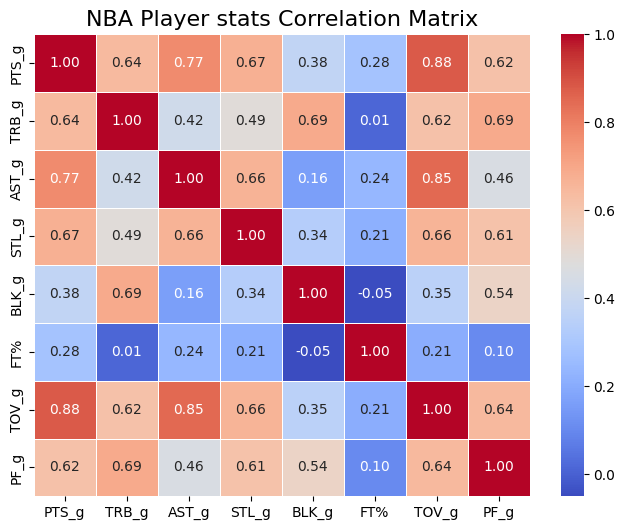

In [40]:
# 그래프 크기 설정 (원하는 크기로 조절)
plt.figure(figsize=(8, 6))

# 히트맵 생성
sns.heatmap(
    correlation_matrix_1,
    annot=True,     # 각 셀에 상관계수 값 표시 여부 (True: 표시)
    cmap='coolwarm', # 색상 팔레트 설정 (양의 상관관계는 따뜻한 색, 음의 상관관계는 차가운 색)
    fmt=".2f",      # 표시되는 숫자의 소수점 자리 수 (소수점 두 자리까지 표시)
    linewidths=.5,  # 셀 경계선 두께
    cbar=True       # 오른쪽에 색상 바(colorbar) 표시 여부
)

# 그래프 제목 설정
plt.title('NBA Player stats Correlation Matrix', fontsize=16)

# 그래프 표시
plt.show()

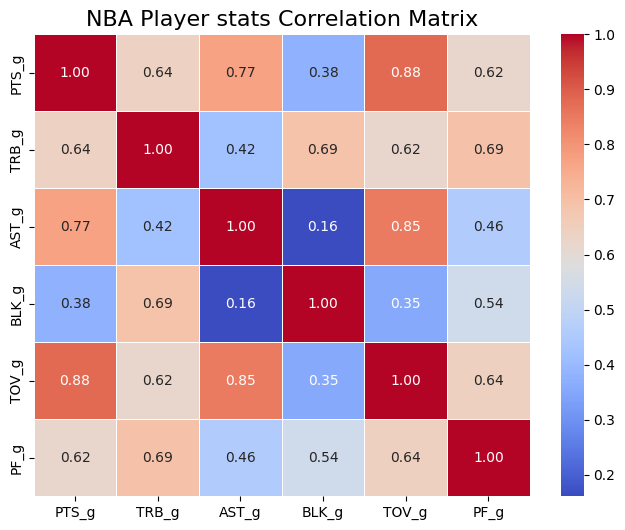

In [41]:
# 그래프 크기 설정 (원하는 크기로 조절)
plt.figure(figsize=(8, 6))

# 히트맵 생성
sns.heatmap(
    correlation_matrix_2,
    annot=True,     # 각 셀에 상관계수 값 표시 여부 (True: 표시)
    cmap='coolwarm', # 색상 팔레트 설정 (양의 상관관계는 따뜻한 색, 음의 상관관계는 차가운 색)
    fmt=".2f",      # 표시되는 숫자의 소수점 자리 수 (소수점 두 자리까지 표시)
    linewidths=.5,  # 셀 경계선 두께
    cbar=True       # 오른쪽에 색상 바(colorbar) 표시 여부
)

# 그래프 제목 설정
plt.title('NBA Player stats Correlation Matrix', fontsize=16)

# 그래프 표시
plt.show()

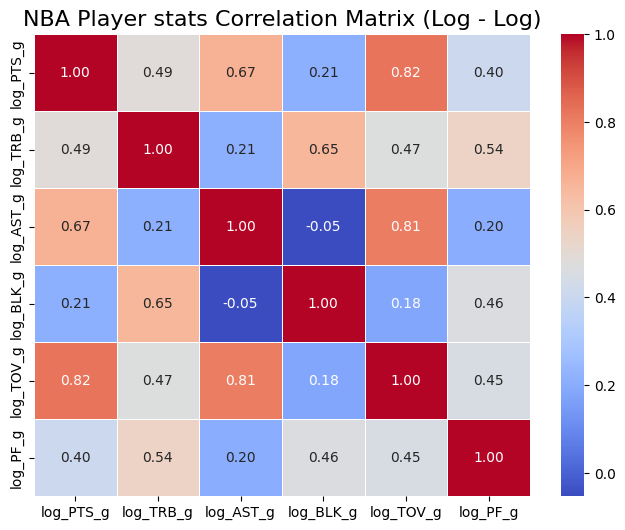

In [42]:
### 로그 모형의 Correlation Matrix
df_log_copy = df_log.drop(columns = ['log_PER','PER'])
correlation_matrix_log = df_log_copy.corr()

plt.figure(figsize=(8, 6))

# 히트맵 생성
sns.heatmap(
    correlation_matrix_log,
    annot=True,     # 각 셀에 상관계수 값 표시 여부 (True: 표시)
    cmap='coolwarm', # 색상 팔레트 설정 (양의 상관관계는 따뜻한 색, 음의 상관관계는 차가운 색)
    fmt=".2f",      # 표시되는 숫자의 소수점 자리 수 (소수점 두 자리까지 표시)
    linewidths=.5,  # 셀 경계선 두께
    cbar=True       # 오른쪽에 색상 바(colorbar) 표시 여부
)

# 그래프 제목 설정
plt.title('NBA Player stats Correlation Matrix (Log - Log)', fontsize=16)

# 그래프 표시
plt.show()

In [43]:
df_log_copy.columns

Index(['log_PTS_g', 'log_TRB_g', 'log_AST_g', 'log_BLK_g', 'log_TOV_g',
       'log_PF_g'],
      dtype='object')

------ 회구모형 변수들의 VIF 계산 ------

In [44]:
def calculate_vif(dataframe):
    # VIF 계산을 위한 데이터프레임 복사 (원본 변경 방지)
    # 함수 인자로 받은 dataframe을 사용합니다.
    df_for_vif = dataframe.copy()

    # VIF 계산을 위해 상수항(intercept)을 추가합니다.
    X = add_constant(df_for_vif)

    # VIF 값을 저장할 빈 DataFrame 생성
    vif_data = pd.DataFrame()
    vif_data["feature"] = X.columns
    vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    # 'const' (상수항)은 VIF 값이 보통 매우 높게 나오므로, 결과에서 제외하고 해석합니다.
    vif_data = vif_data[vif_data['feature'] != 'const']

    # VIF 값을 기준으로 내림차순 정렬하여 반환
    return vif_data.sort_values(by="VIF", ascending=False)

In [45]:
print("--- 다중선형회귀모형_1 에 대한 VIF ---")
vif_result_1 = calculate_vif(nba_data_df_1_copy)
print(vif_result_1)

print("\n--- 다중선형회귀모형_2 에 대한 VIF ---")
vif_result_2 = calculate_vif(nba_data_df_2_copy)
print(vif_result_2)

print("\n--- Log - Log 비선형 모형 에 대한 VIF ---")
vif_result_3 = calculate_vif(df_log_copy)
print(vif_result_3)

--- 다중선형회귀모형_1 에 대한 VIF ---
  feature       VIF
7   TOV_g  7.607359
1   PTS_g  5.421382
3   AST_g  4.628148
2   TRB_g  3.270062
8    PF_g  2.649538
4   STL_g  2.384642
5   BLK_g  2.081768
6     FT%  1.162411

--- 다중선형회귀모형_2 에 대한 VIF ---
  feature       VIF
5   TOV_g  7.469262
1   PTS_g  4.919331
3   AST_g  4.094047
2   TRB_g  3.192394
6    PF_g  2.344029
4   BLK_g  2.060823

--- Log - Log 비선형 모형 에 대한 VIF ---
     feature       VIF
5  log_TOV_g  5.857169
3  log_AST_g  3.399017
1  log_PTS_g  3.261459
2  log_TRB_g  2.468600
4  log_BLK_g  1.955584
6   log_PF_g  1.653672


------- Log - Log 비선형 모형 + 더미 변수 -------

In [46]:
df_log_pos = df_log.drop(columns = ['PER'])
df_log_pos['Pos_x'] = Merged_df['Pos_x']

In [47]:
df_log_pos.head(5)

,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g,log_PER,Pos_x
0,3.551258,2.326581,2.379546,0.433636,1.615136,1.140576,3.335770,PG
1,3.435706,1.876917,1.974081,0.638339,1.150572,1.239340,3.377588,PG
2,3.448029,2.527371,2.017639,0.733421,1.487193,1.354987,3.397858,PF
3,3.392065,1.528312,2.046435,0.156004,1.228349,1.054357,3.152736,PG
4,3.310266,2.591848,2.298780,0.620985,1.386294,1.240024,3.433987,C


In [48]:
df_log_dummy = pd.get_dummies(df_log_pos, columns=['Pos_x'], drop_first=True, dtype=int)

In [49]:
df_log_dummy.head(5)

,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g,log_PER,Pos_x_PF,Pos_x_PG,Pos_x_SF,Pos_x_SG
0,3.551258,2.326581,2.379546,0.433636,1.615136,1.140576,3.335770,0,1,0,0
1,3.435706,1.876917,1.974081,0.638339,1.150572,1.239340,3.377588,0,1,0,0
2,3.448029,2.527371,2.017639,0.733421,1.487193,1.354987,3.397858,1,0,0,0
3,3.392065,1.528312,2.046435,0.156004,1.228349,1.054357,3.152736,0,1,0,0
4,3.310266,2.591848,2.298780,0.620985,1.386294,1.240024,3.433987,0,0,0,0


In [50]:
df_log_dummy.head(5)

,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g,log_PER,Pos_x_PF,Pos_x_PG,Pos_x_SF,Pos_x_SG
0,3.551258,2.326581,2.379546,0.433636,1.615136,1.140576,3.335770,0,1,0,0
1,3.435706,1.876917,1.974081,0.638339,1.150572,1.239340,3.377588,0,1,0,0
2,3.448029,2.527371,2.017639,0.733421,1.487193,1.354987,3.397858,1,0,0,0
3,3.392065,1.528312,2.046435,0.156004,1.228349,1.054357,3.152736,0,1,0,0
4,3.310266,2.591848,2.298780,0.620985,1.386294,1.240024,3.433987,0,0,0,0


In [51]:
# 종속 변수와 독립 변수 설정
y_log_dummy = df_log_dummy['log_PER']

# 'Player' 컬럼은 더미 변수가 아니므로 직접 제거해줍니다.
X_log_dummy = df_log_dummy.drop(['log_PER'], axis = 1)

# 상수항 추가
X_log_dummy = sm.add_constant(X_log_dummy)

# OLS 모델 적합
model_log_dummy = sm.OLS(y_log_dummy, X_log_dummy)
results_model_log_dummy = model_log_dummy.fit()

print("\n--- 회귀 분석 결과 요약 (더미 변수 포함) ---")
print(results_model_log_dummy.summary())


--- 회귀 분석 결과 요약 (더미 변수 포함) ---
                            OLS Regression Results                            
Dep. Variable:                log_PER   R-squared:                       0.743
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     83.55
Date:                Thu, 26 Jun 2025   Prob (F-statistic):           3.27e-79
Time:                        06:40:54   Log-Likelihood:                 164.80
No. Observations:                 300   AIC:                            -307.6
Df Residuals:                     289   BIC:                            -266.9
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.780

------- 분산함수 추정 (이분산) -------

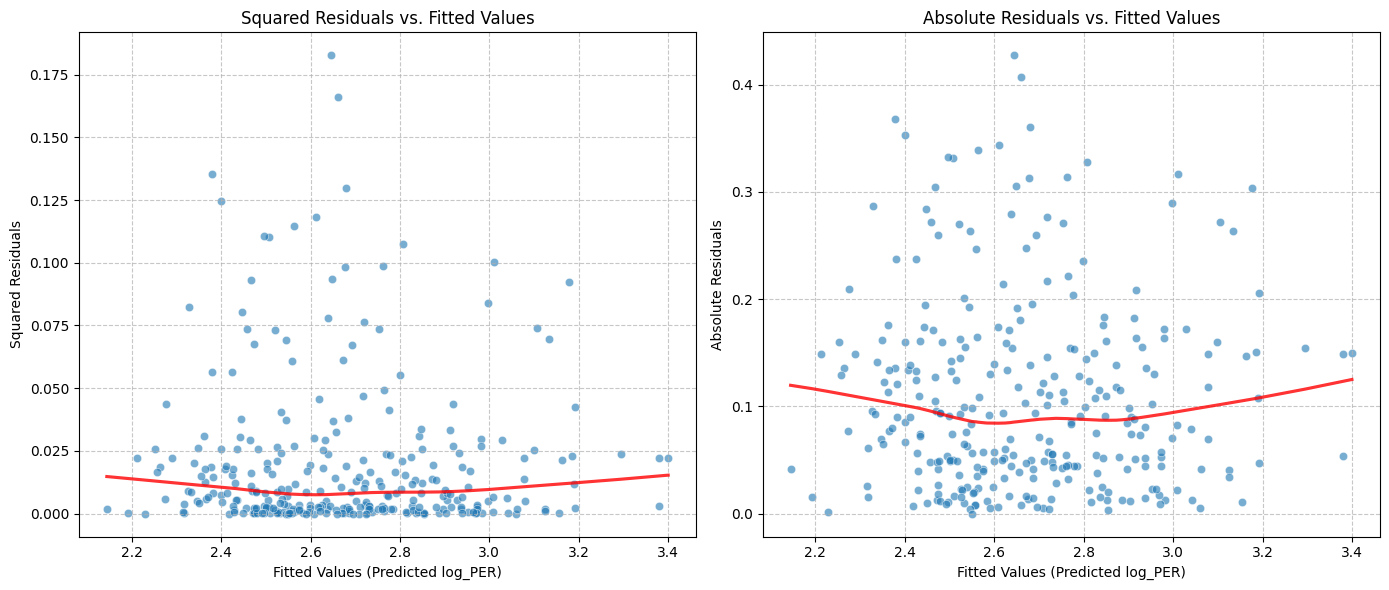


--- 잔차의 제곱/절대값 플롯 해석 가이드 ---
이상적인 경우 (등분산성 만족): 점들이 수평선 주변에 무작위로 분포하며 빨간색 LOESS 선이 평평해야 합니다.
이분산성 의심: 빨간색 LOESS 선이 상승하거나 하강하는 추세, 또는 깔때기/역깔때기 모양으로 점이 퍼져 있다면 이분산성이 존재할 수 있습니다.


In [52]:
# ====================================================================
# 분산 함수 추정을 위한 플롯 그리기
# ====================================================================

# 잔차의 제곱
squared_residuals = results_model_log_dummy.resid**2
# 잔차의 절대값 (덜 민감하게 반응하여 패턴을 더 잘 보여줄 수 있음)
abs_residuals = np.abs(results_model_log_dummy.resid)

plt.figure(figsize=(14, 6))

# 1. 잔차의 제곱 vs. 예측값 (Fitted Values)
plt.subplot(1, 2, 1)
sns.scatterplot(x=results_model_log_dummy.fittedvalues, y=squared_residuals, alpha=0.6)
# LOESS (Locally Estimated Scatterplot Smoothing) 선을 추가하여 추세를 확인
sns.regplot(x=results_model_log_dummy.fittedvalues, y=squared_residuals,
            scatter=False, lowess=True, color='red', line_kws={'alpha': 0.8})
plt.xlabel("Fitted Values (Predicted log_PER)")
plt.ylabel("Squared Residuals")
plt.title("Squared Residuals vs. Fitted Values")
plt.grid(True, linestyle='--', alpha=0.7)

# 2. 잔차의 절대값 vs. 예측값 (Fitted Values)
plt.subplot(1, 2, 2)
sns.scatterplot(x=results_model_log_dummy.fittedvalues, y=abs_residuals, alpha=0.6)
sns.regplot(x=results_model_log_dummy.fittedvalues, y=abs_residuals,
            scatter=False, lowess=True, color='red', line_kws={'alpha': 0.8})
plt.xlabel("Fitted Values (Predicted log_PER)")
plt.ylabel("Absolute Residuals")
plt.title("Absolute Residuals vs. Fitted Values")
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

print("\n--- 잔차의 제곱/절대값 플롯 해석 가이드 ---")
print("이상적인 경우 (등분산성 만족): 점들이 수평선 주변에 무작위로 분포하며 빨간색 LOESS 선이 평평해야 합니다.")
print("이분산성 의심: 빨간색 LOESS 선이 상승하거나 하강하는 추세, 또는 깔때기/역깔때기 모양으로 점이 퍼져 있다면 이분산성이 존재할 수 있습니다.")

----- 이분산 검정 -------

In [53]:

from statsmodels.stats.api import het_breuschpagan, het_white # 이분산성 검정 함수 임포트

# ----------------------------------------------------------------------------

# 모델에 사용될 최종 독립변수 선택 (더미 변수 포함)
independent_vars_for_model = [
    'const', # 상수항
    'log_PTS_g', 'log_TRB_g', 'log_AST_g', 'log_BLK_g',
    'log_TOV_g', 'log_PF_g',
]

# OLS 모델 학습
results_test = model_log2.fit()

print("--- OLS Regression Results for Heteroscedasticity Test ---")
print(results_test.summary())

# ----------------------------------------------------------------------------
# 2. 이분산성 검정 수행

# 잔차와 독립변수 가져오기
residuals = results_test.resid
exog_vars = results_test.model.exog # 학습에 사용된 독립변수 (상수항 포함)

print("\n--- Breusch-Pagan Test for Heteroscedasticity ---")
# Breusch-Pagan 검정
# (LM stat, LM p-value, F-stat, F p-value)
# H0: 등분산성 (Homoscedasticity)
# H1: 이분산성 (Heteroscedasticity)
bp_test = het_breuschpagan(residuals, exog_vars)
print(f"LM Statistic: {bp_test[0]:.4f}")
print(f"LM p-value: {bp_test[1]:.4f}")
print(f"F-Statistic: {bp_test[2]:.4f}")
print(f"F p-value: {bp_test[3]:.4f}")

if bp_test[1] < 0.05: # 일반적으로 유의수준 0.05 사용
    print("결과: p-value가 0.05보다 작으므로 귀무가설(등분산성)을 기각합니다.")
    print("      즉, 이분산성이 존재할 가능성이 높습니다.")
else:
    print("결과: p-value가 0.05보다 크므로 귀무가설(등분산성)을 기각할 수 없습니다.")
    print("      즉, 등분산성이 존재한다고 볼 수 있습니다.")

print("\n--- White Test for Heteroscedasticity ---")
# White 검정
# (LM stat, LM p-value, F-stat, F p-value)
# H0: 등분산성 (Homoscedasticity)
# H1: 이분산성 (Heteroscedasticity)
white_test = het_white(residuals, exog_vars)
print(f"LM Statistic: {white_test[0]:.4f}")
print(f"LM p-value: {white_test[1]:.4f}")
print(f"F-Statistic: {white_test[2]:.4f}")
print(f"F p-value: {white_test[3]:.4f}")

if white_test[1] < 0.05:
    print("결과: p-value가 0.05보다 작으므로 귀무가설(등분산성)을 기각합니다.")
    print("      즉, 이분산성이 존재할 가능성이 높습니다.")
else:
    print("결과: p-value가 0.05보다 크므로 귀무가설(등분산성)을 기각할 수 없습니다.")
    print("      즉, 등분산성이 존재한다고 볼 수 있습니다.")

--- OLS Regression Results for Heteroscedasticity Test ---
                            OLS Regression Results                            
Dep. Variable:                log_PER   R-squared:                       0.664
Model:                            OLS   Adj. R-squared:                  0.657
Method:                 Least Squares   F-statistic:                     96.43
Date:                Thu, 26 Jun 2025   Prob (F-statistic):           2.13e-66
Time:                        06:40:54   Log-Likelihood:                 124.52
No. Observations:                 300   AIC:                            -235.0
Df Residuals:                     293   BIC:                            -209.1
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

In [54]:
# 종속 변수와 독립 변수 설정
y_log_dummy = df_log_dummy['log_PER']

# 'Player' 컬럼은 더미 변수가 아니므로 직접 제거해줍니다.
X_log_dummy = df_log_dummy.drop(['log_PER'], axis = 1)

# 상수항 추가
X_log_dummy = sm.add_constant(X_log_dummy)

# OLS 모델 학습 (이분산성 검정을 위해 nonrobust 모델 사용)
model_log_dummy = sm.OLS(y_log_dummy, X_log_dummy)
results_ols = model_log_dummy.fit()

print("--- Initial OLS Regression Results (for comparison) ---")
print(results_ols.summary())

# ----------------------------------------------------------------------------
# 2. WLS (Weighted Least Squares) 적용

# 잔차의 절댓값을 예측값으로 회귀하여 분산의 패턴을 추정
# 가장 일반적인 방법 중 하나는 OLS 잔차의 제곱 또는 절댓값에 대한 회귀를 통해 분산 함수를 추정하는 것입니다.
# 여기서는 잔차의 절댓값에 대해 예측값(fitted values)으로 회귀하는 방식을 사용해봅니다.
# 잔차 산점도 image_df2544.png를 보면 Fitted Values가 증가함에 따라 Absolute Residuals가 증가하는 경향이 있습니다.

# Step 1: OLS 모델에서 얻은 잔차의 절댓값을 종속변수로, 예측값을 독립변수로 하여 보조 회귀 수행
# OLS의 잔차
abs_residuals = np.abs(results_ols.resid)
# OLS의 예측값 (fitted values)
fitted_values = results_ols.fittedvalues

# 보조 회귀 모델 (잔차의 절댓값 = f(예측값))
# 상수항 추가
fitted_values_with_const = sm.add_constant(fitted_values)
aux_model = sm.OLS(abs_residuals, fitted_values_with_const)
aux_results = aux_model.fit()

# Step 2: 추정된 분산 함수를 사용하여 가중치 계산
# 추정된 오차 분산 (sigma_i^2)은 보조 회귀의 예측값의 제곱에 비례한다고 가정
# 예: sigma_i^2 = (fitted_values * beta_aux_1 + beta_aux_0)^2
# 가중치 (weights)는 분산의 역수
# 0으로 나누는 것을 방지하기 위해 작은 값을 더하거나, 가중치가 0이 되지 않도록 처리
# fitted_values가 음수가 될 수 있으므로 np.abs를 사용하거나, 로그 변환된 예측값을 사용하는 것이 더 안전합니다.
# 여기서는 가장 간단한 형태로, fitted values 자체가 분산과 관련 있다고 가정하고 weights를 계산합니다.
# 만약 로그 변환된 PER (y_log_data)의 분산 추정이라면, exp(fitted_values)를 사용하는 것이 더 논리적일 수 있습니다.
# 예를 들어, sigma_i^2 = exp(fitted_values) 라고 가정하면 weights = 1 / exp(fitted_values)
# 혹은 단순히 sigma_i^2 = fitted_values^2 로 가정하면 weights = 1 / fitted_values^2
# image_df2544.png에서 Squared Residuals와 Absolute Residuals 모두 Fitted Values에 따라 증가하는 패턴을 보입니다.
# 여기서는 간단하게 fitted_values의 역수를 가중치로 사용하거나, 더 일반적으로는 fitted_values의 제곱의 역수를 사용해 보겠습니다.
# 실제로는 가장 적절한 가중치 함수를 찾는 과정이 필요합니다.
# 여기서는 fitted_values의 절댓값이 0에 가까워지는 경우를 피하기 위해 작은 상수를 더합니다.

# 가중치 계산 (다양한 방법 중 하나)
# 1) 가장 단순하게, 잔차의 분산이 예측값의 제곱에 비례한다고 가정:
# weights = 1 / (fitted_values**2) # 주의: fitted_values에 0이 있으면 오류

# 2) 잔차의 분산이 fitted values의 어떤 함수 f(fitted_values)에 비례한다고 가정할 때,
#    f(fitted_values)를 추정하는 보조회귀 (fitted values에 대한 OLS)
#    여기서는 보조회귀의 예측값을 사용하여 분산의 추정치로 활용합니다.
#    hat_sigma_i_squared = (aux_results.fittedvalues)**2 # 보조회귀 예측값의 제곱
#    weights = 1 / hat_sigma_i_squared
#    weights = np.clip(weights, 0, 1e10) # 너무 큰 가중치 방지 (발산 방지)

# 3) statsmodels 예제에서 흔히 사용하는 방법: 잔차의 절댓값으로 나누기 (WLS)
#    여기서 weights는 분산의 역수로 사용되므로, 표준편차의 역수로 사용될 때와는 다릅니다.
#    WLS에서는 분산의 역수를 `weights` 인자로 전달합니다.
#    residual_std = np.sqrt(np.abs(results_ols.resid))
#    weights = 1 / residual_std # 각 관측치의 표준편차의 역수를 가중치로 사용

# 여기서는 White 검정처럼 이분산성의 형태를 독립변수의 제곱항 등으로 고려할 수 있지만,
# 보통은 잔차의 절댓값 또는 잔차 제곱에 대한 보조 회귀를 통해 분산 함수를 추정합니다.
# 가장 일반적인 WLS 적용을 위해, 잔차의 표준편차 추정치(sqrt(abs(residuals)))의 역수를 사용해 봅시다.
# 잔차의 절대값이 0에 가까울 때 문제가 생길 수 있으므로, 작은 값 epsilon을 더해줍니다.
epsilon = 1e-6
weights_wls = 1 / (np.abs(results_ols.resid) + epsilon)
# 혹은 분산의 역수를 가중치로 사용한다면,
# weights_wls = 1 / ((results_ols.resid)**2 + epsilon) # 잔차 제곱의 역수

# 3. WLS 모델 학습
model_wls = sm.WLS(y_log_dummy, X_log_dummy, weights=weights_wls)
results_wls = model_wls.fit()

print("\n--- WLS Regression Results (after addressing Heteroscedasticity) ---")
print(results_wls.summary())

# OLS (robust std err) 결과와 WLS 결과를 비교
# image_e0190a.png는 Robust Std Errors를 사용한 OLS 결과입니다.
# WLS는 표준 오차와 계수 모두 변경될 수 있으며, Robust Std Errors는 표준 오차만 변경합니다.
# 두 결과를 함께 제시하여 이분산성 처리 방안의 차이와 결과를 비교하는 것이 좋습니다.

--- Initial OLS Regression Results (for comparison) ---
                            OLS Regression Results                            
Dep. Variable:                log_PER   R-squared:                       0.743
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     83.55
Date:                Thu, 26 Jun 2025   Prob (F-statistic):           3.27e-79
Time:                        06:40:54   Log-Likelihood:                 164.80
No. Observations:                 300   AIC:                            -307.6
Df Residuals:                     289   BIC:                            -266.9
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------

In [55]:
print(results_wls.summary())

                            WLS Regression Results                            
Dep. Variable:                log_PER   R-squared:                       0.945
Model:                            WLS   Adj. R-squared:                  0.943
Method:                 Least Squares   F-statistic:                     492.8
Date:                Thu, 26 Jun 2025   Prob (F-statistic):          4.25e-175
Time:                        06:40:54   Log-Likelihood:                 309.59
No. Observations:                 300   AIC:                            -597.2
Df Residuals:                     289   BIC:                            -556.4
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.7819      0.031     56.886      0.0

------- 강건한 표준오차 (Robust Standard Errors) --------

In [56]:
df_20242025_total = pd.read_csv('/content/drive/MyDrive/Econometrics_Project_PNU/nba20242025_total.txt', delimiter = ',')
df_20242025_advanced = pd.read_csv('/content/drive/MyDrive/Econometrics_Project_PNU/nba20242025_advanced.txt', delimiter = ',')

In [57]:
Merged_df_predict = pd.merge(df_20242025_total, df_20242025_advanced, on = 'Player')
Merged_df_predict.head(5)

,Rk_x,Player,Age_x,Team_x,Pos_x,G_x,GS_x,MP_x,FG,FGA,...,OWS,DWS,WS,WS/48,OBPM,DBPM,BPM,VORP,Awards_y,Player-additional_y
0,1,Shai Gilgeous-Alexander,26,OKC,PG,76,76,2598,860,1656,...,11.9,4.8,16.7,0.309,8.9,2.6,11.5,8.9,NaN,gilgesh01
1,2,Anthony Edwards,23,MIN,SG,79,79,2871,721,1612,...,4.6,3.8,8.4,0.140,4.4,0.0,4.3,4.6,NaN,edwaran01
2,3,Nikola Jokić,29,DEN,C,70,70,2571,786,1364,...,12.7,3.8,16.4,0.307,9.9,3.3,13.3,9.8,NaN,jokicni01
3,4,Giannis Antetokounmpo,30,MIL,PF,67,67,2289,793,1319,...,7.8,3.7,11.5,0.241,6.9,2.5,9.5,6.6,NaN,antetgi01
4,5,Jayson Tatum,26,BOS,PF,72,72,2624,662,1465,...,5.3,4.2,9.5,0.174,4.4,0.8,5.2,4.8,NaN,tatumja01


In [58]:
columns_need2 = ['Player', 'G_x', 'PTS', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PER', 'Pos_x']
Merged_df_predict = Merged_df_predict[columns_need2]
##  결측치 (NaN)가 있는 행 제거(전체 열)
Merged_df_predict = Merged_df_predict.dropna()

## 0 있는 행 제거(G_x만 정리)
Merged_df_predict = Merged_df_predict[Merged_df_predict['G_x'] != 0]

In [59]:
Merged_df_predict.columns

Index(['Player', 'G_x', 'PTS', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PER',
       'Pos_x'],
      dtype='object')

In [60]:
nba_data_df_predict = pd.DataFrame(columns = columns_original_need)
nba_data_df_predict = nba_data_df_predict.drop(columns = ['STL_g', 'FT%', 'FGF_g'])
nba_data_df_predict.columns

Index(['Player', 'PER', 'PTS_g', 'TRB_g', 'AST_g', 'BLK_g', 'TOV_g', 'PF_g',
       'Pos_x'],
      dtype='object')

In [61]:
nba_data_df_predict['Player'] = Merged_df_predict['Player']
nba_data_df_predict['Pos_x'] = Merged_df_predict['Pos_x']
nba_data_df_predict['PER'] = Merged_df_predict['PER']
nba_data_df_predict['PTS_g'] = Merged_df_predict['PTS'] / Merged_df_predict['G_x']
nba_data_df_predict['TRB_g'] = Merged_df_predict['TRB'] / Merged_df_predict['G_x']
nba_data_df_predict['AST_g'] = Merged_df_predict['AST'] / Merged_df_predict['G_x']
nba_data_df_predict['BLK_g'] = Merged_df_predict['BLK'] / Merged_df_predict['G_x']
nba_data_df_predict['TOV_g'] = Merged_df_predict['TOV'] / Merged_df_predict['G_x']
nba_data_df_predict['PF_g'] = Merged_df_predict['PF'] / Merged_df_predict['G_x']
nba_data_df_predict = nba_data_df_predict.head(300)
nba_data_df_predict

,Player,PER,PTS_g,TRB_g,AST_g,BLK_g,TOV_g,PF_g,Pos_x
0,Shai Gilgeous-Alexander,30.7,32.684211,4.986842,6.394737,1.013158,2.407895,2.157895,PG
1,Anthony Edwards,20.1,27.556962,5.696203,4.544304,0.645570,3.151899,1.898734,SG
2,Nikola Jokić,32.0,29.585714,12.742857,10.228571,0.642857,3.285714,2.285714,C
3,Giannis Antetokounmpo,30.5,30.388060,11.910448,6.462687,1.164179,3.074627,2.313433,PF
4,Jayson Tatum,21.7,26.833333,8.652778,5.986111,0.527778,2.902778,2.180556,PF
...,...,...,...,...,...,...,...,...,...
295,Isaac Okoro,10.7,6.127273,2.363636,1.236364,0.290909,0.418182,1.890909,SG
296,Svi Mykhailiuk,9.8,8.789474,2.368421,2.000000,0.184211,1.368421,1.131579,SF
297,Mason Plumlee,14.8,4.500000,6.148649,1.810811,0.635135,0.797297,2.081081,C
298,Ben Sheppard,9.2,5.269841,2.809524,1.349206,0.222222,0.349206,1.984127,SG


In [62]:
df_20242025 = nba_data_df_predict.copy()

# 종속변수와 독립변수 목록 정의
dependent_variable = 'PER'
independent_variables = ['PTS_g', 'TRB_g', 'AST_g', 'BLK_g', 'TOV_g', 'PF_g']

# 독립변수들에 로그 변환 적용
print("독립변수 로그 변환 시작...")
for col in independent_variables:
    # 새로운 컬럼 이름은 'log_' 접두사를 사용합니다.
    df_20242025[f'log_{col}'] = np.log1p(df_20242025[col])
    print(f"  - '{col}' 변환 완료 -> 'log_{col}' 생성")

df_20242025[f'log_{dependent_variable}'] = np.log(df_20242025[dependent_variable])
print(f"'{dependent_variable}' 컬럼에 log(x) 변환 완료 -> 'log_{dependent_variable}' 생성")

print("\n로그 변환 후 DataFrame의 상위 5행:")
df_20242025.head(5)

독립변수 로그 변환 시작...
  - 'PTS_g' 변환 완료 -> 'log_PTS_g' 생성
  - 'TRB_g' 변환 완료 -> 'log_TRB_g' 생성
  - 'AST_g' 변환 완료 -> 'log_AST_g' 생성
  - 'BLK_g' 변환 완료 -> 'log_BLK_g' 생성
  - 'TOV_g' 변환 완료 -> 'log_TOV_g' 생성
  - 'PF_g' 변환 완료 -> 'log_PF_g' 생성
'PER' 컬럼에 log(x) 변환 완료 -> 'log_PER' 생성

로그 변환 후 DataFrame의 상위 5행:


,Player,PER,PTS_g,TRB_g,AST_g,BLK_g,TOV_g,PF_g,Pos_x,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g,log_PER
0,Shai Gilgeous-Alexander,30.7,32.684211,4.986842,6.394737,1.013158,2.407895,2.157895,PG,3.517029,1.789564,2.000769,0.699705,1.226095,1.149906,3.424263
1,Anthony Edwards,20.1,27.556962,5.696203,4.544304,0.645570,3.151899,1.898734,SG,3.351901,1.901541,1.712771,0.498087,1.423566,1.064274,3.000720
2,Nikola Jokić,32.0,29.585714,12.742857,10.228571,0.642857,3.285714,2.285714,C,3.420533,2.620519,2.418462,0.496437,1.455287,1.189584,3.465736
3,Giannis Antetokounmpo,30.5,30.388060,11.910448,6.462687,1.164179,3.074627,2.313433,PF,3.446428,2.558037,2.009915,0.772041,1.404779,1.197985,3.417727
4,Jayson Tatum,21.7,26.833333,8.652778,5.986111,0.527778,2.902778,2.180556,PF,3.326234,2.267246,1.943924,0.423814,1.361689,1.157056,3.077312


In [63]:
simple_columns = ['Player', 'Pos_x', 'PER', 'log_PER', 'log_PTS_g', 'log_TRB_g', 'log_AST_g', 'log_BLK_g', 'log_TOV_g', 'log_PF_g']
nba_data_df_predict_log = df_20242025[simple_columns]
nba_data_df_predict_log.head(10)

,Player,Pos_x,PER,log_PER,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g
0,Shai Gilgeous-Alexander,PG,30.7,3.424263,3.517029,1.789564,2.000769,0.699705,1.226095,1.149906
1,Anthony Edwards,SG,20.1,3.000720,3.351901,1.901541,1.712771,0.498087,1.423566,1.064274
2,Nikola Jokić,C,32.0,3.465736,3.420533,2.620519,2.418462,0.496437,1.455287,1.189584
3,Giannis Antetokounmpo,PF,30.5,3.417727,3.446428,2.558037,2.009915,0.772041,1.404779,1.197985
4,Jayson Tatum,PF,21.7,3.077312,3.326234,2.267246,1.943924,0.423814,1.361689,1.157056
5,Devin Booker,SG,19.3,2.960105,3.282414,1.622683,2.086086,0.193371,1.369487,1.291984
6,Trae Young,PG,18.3,2.906901,3.227783,1.412270,2.532025,0.146603,1.735375,1.067429
7,Tyler Herro,SG,19.7,2.980619,3.214711,1.821612,1.872801,0.199489,1.272966,0.743791
8,Cade Cunningham,PG,20.6,3.025291,3.301114,1.956063,2.313949,0.563689,1.689041,1.331235
9,James Harden,PG,20.0,2.995732,3.170111,1.912819,2.271734,0.528392,1.670807,1.115349


In [64]:
### 더미변수 추가하고 PER 상위 30명 내림차순으로 정리
# 'Predicted_PER' 컬럼을 기준으로 내림차순 정렬
# ascending=False 옵션을 사용하여 내림차순으로 정렬합니다.
nba_data_df_predict_log = nba_data_df_predict_log.sort_values(by='PER', ascending=False)
nba_data_df_predict_log = nba_data_df_predict_log.head(30)
nba_data_df_predict_log.head(5)

,Player,Pos_x,PER,log_PER,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g
2,Nikola Jokić,C,32.0,3.465736,3.420533,2.620519,2.418462,0.496437,1.455287,1.189584
0,Shai Gilgeous-Alexander,PG,30.7,3.424263,3.517029,1.789564,2.000769,0.699705,1.226095,1.149906
3,Giannis Antetokounmpo,PF,30.5,3.417727,3.446428,2.558037,2.009915,0.772041,1.404779,1.197985
140,Zion Williamson,PF,27.3,3.306887,3.241289,2.104134,1.840550,0.641854,1.386294,1.317301
50,Anthony Davis,PF,26.3,3.269569,3.247482,2.531204,1.514912,1.149579,1.168041,1.072121


In [65]:
### 더미변수 생성
nba_data_df_predict_log_dummy = pd.get_dummies(nba_data_df_predict_log, columns=['Pos_x'], drop_first=True, dtype=int)
nba_data_df_predict_log_dummy.head(5)

,Player,PER,log_PER,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g,Pos_x_PF,Pos_x_PG,Pos_x_SF,Pos_x_SG
2,Nikola Jokić,32.0,3.465736,3.420533,2.620519,2.418462,0.496437,1.455287,1.189584,0,0,0,0
0,Shai Gilgeous-Alexander,30.7,3.424263,3.517029,1.789564,2.000769,0.699705,1.226095,1.149906,0,1,0,0
3,Giannis Antetokounmpo,30.5,3.417727,3.446428,2.558037,2.009915,0.772041,1.404779,1.197985,1,0,0,0
140,Zion Williamson,27.3,3.306887,3.241289,2.104134,1.840550,0.641854,1.386294,1.317301,1,0,0,0
50,Anthony Davis,26.3,3.269569,3.247482,2.531204,1.514912,1.149579,1.168041,1.072121,1,0,0,0


In [66]:
trained_model_columns = results_model_log_dummy.params.index.tolist()
trained_model_columns

['const',
 'log_PTS_g',
 'log_TRB_g',
 'log_AST_g',
 'log_BLK_g',
 'log_TOV_g',
 'log_PF_g',
 'Pos_x_PF',
 'Pos_x_PG',
 'Pos_x_SF',
 'Pos_x_SG']

In [67]:
nba_data_df_predict_log_dummy.columns

Index(['Player', 'PER', 'log_PER', 'log_PTS_g', 'log_TRB_g', 'log_AST_g',
       'log_BLK_g', 'log_TOV_g', 'log_PF_g', 'Pos_x_PF', 'Pos_x_PG',
       'Pos_x_SF', 'Pos_x_SG'],
      dtype='object')

------ OLS 모형을 통한 예측값 -------

In [68]:
#### 예측을 위한 코드.
independent_vars_for_model = ['log_PTS_g', 'log_TRB_g', 'log_AST_g', 'log_BLK_g','log_TOV_g', 'log_PF_g','Pos_x_PF', 'Pos_x_PG', 'Pos_x_SF', 'Pos_x_SG']

# ----------------------------------------------------------------------------
# 3. 예측을 위한 독립변수 DataFrame 구성 및 전처리

# 학습 모델의 독립변수 컬럼명 가져오기 (상수항 포함)
trained_model_columns = results_model_log_dummy.params.index.tolist()

# nba_data_df_predict_log_dummy 에서 예측에 필요한 컬럼만 선택
# 학습 모델에 사용된 컬럼들만 예측 데이터에서 선택
X_predict_data = nba_data_df_predict_log_dummy[independent_vars_for_model].copy() # independent_vars_for_model는 위에서 정의됨

# 상수항 추가 (모델 학습 시 상수항을 추가했으므로 예측 시에도 추가해야 함)
X_predict_data = sm.add_constant(X_predict_data, has_constant='add') # 이미 상수항이 있다면 추가하지 않도록 'add' 사용

# 컬럼 순서 맞추기 (매우 중요!)
# 예측 데이터의 컬럼 순서가 학습 모델의 컬럼 순서와 정확히 일치해야 합니다.
if not all(X_predict_data.columns == trained_model_columns):
    print("경고: 예측 데이터의 컬럼 순서가 학습 모델과 다릅니다. 재정렬합니다.")
    print("학습 모델 컬럼:", trained_model_columns)
    print("예측 데이터 컬럼 (정렬 전):", X_predict_data.columns.tolist())
    X_predict_data = X_predict_data[trained_model_columns]
    print("예측 데이터 컬럼 (정렬 후):", X_predict_data.columns.tolist())

# ----------------------------------------------------------------------------
# 4. 예측 수행
predicted_log_PER = results_model_log_dummy.predict(X_predict_data)

# ----------------------------------------------------------------------------
# 5. 예측된 log_PER을 실제 PER 값으로 변환
# np.log를 사용하여 log_PER을 계산했으므로, np.exp를 사용하여 역변환합니다.
predicted_PER = np.exp(predicted_log_PER)

# ----------------------------------------------------------------------------
# 6. 결과 정리 및 비교
nba_data_df_predict_log_dummy['Predicted_log_PER'] = predicted_log_PER
nba_data_df_predict_log_dummy['Predicted_PER'] = predicted_PER

# 실제 log_PER, 실제 PER, 예측 log_PER, 예측 PER을 비교
comparison_df = nba_data_df_predict_log_dummy[['Player', 'PER', 'Predicted_PER']]
comparison_df['Absolute_Error_PER'] = np.abs(comparison_df['PER'] - comparison_df['Predicted_PER'])
comparison_df['Percentage_Error_PER'] = (comparison_df['Absolute_Error_PER'] / comparison_df['PER']) * 100

# 전체 평균 절대 오차 및 #평균 절대 및 백분율 오차
mean_abs_error = comparison_df['Absolute_Error_PER'].mean()
mean_perc_error = comparison_df['Percentage_Error_PER'].mean()
print(f"\n평균 절대 오차 (PER): {mean_abs_error:.2f}")
print(f"평균 백분율 오차 (PER): {mean_perc_error:.2f}%")
comparison_df


평균 절대 오차 (PER): 2.83
평균 백분율 오차 (PER): 11.83%


/tmp/ipython-input-68-719839583.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  comparison_df['Absolute_Error_PER'] = np.abs(comparison_df['PER'] - comparison_df['Predicted_PER'])
/tmp/ipython-input-68-719839583.py:43: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  comparison_df['Percentage_Error_PER'] = (comparison_df['Absolute_Error_PER'] / comparison_df['PER']) * 100


,Player,PER,Predicted_PER,Absolute_Error_PER,Percentage_Error_PER
2,Nikola Jokić,32.0,30.648757,1.351243,4.222633
0,Shai Gilgeous-Alexander,30.7,23.042240,7.657760,24.943845
3,Giannis Antetokounmpo,30.5,24.618001,5.881999,19.285242
140,Zion Williamson,27.3,19.325668,7.974332,29.210008
50,Anthony Davis,26.3,24.367833,1.932167,7.346642
153,Daniel Gafford,24.7,19.530277,5.169723,20.930053
70,Victor Wembanyama,24.2,28.796435,4.596435,18.993535
32,Luka Dončić,24.1,20.900682,3.199318,13.275180
168,Mark Williams,23.9,22.552812,1.347188,5.636771
10,Karl-Anthony Towns,23.4,23.579302,0.179302,0.766250


------- WLS 모형을 통한 예측값 -------

In [69]:
# 3. WLS 모델 학습
model_wls = sm.WLS(y_log_dummy, X_log_dummy, weights=weights_wls)
results_wls = model_wls.fit()

#### 예측을 위한 코드.
independent_vars_for_model = ['log_PTS_g', 'log_TRB_g', 'log_AST_g', 'log_BLK_g','log_TOV_g', 'log_PF_g','Pos_x_PF', 'Pos_x_PG', 'Pos_x_SF', 'Pos_x_SG']

# ----------------------------------------------------------------------------
# 3. 예측을 위한 독립변수 DataFrame 구성 및 전처리

# 학습 모델의 독립변수 컬럼명 가져오기 (상수항 포함)
trained_model_columns = results_wls.params.index.tolist()

# nba_data_df_predict_log_dummy 에서 예측에 필요한 컬럼만 선택
# 학습 모델에 사용된 컬럼들만 예측 데이터에서 선택
X_predict_data = nba_data_df_predict_log_dummy[independent_vars_for_model].copy() # independent_vars_for_model는 위에서 정의됨

# 상수항 추가 (모델 학습 시 상수항을 추가했으므로 예측 시에도 추가해야 함)
X_predict_data = sm.add_constant(X_predict_data, has_constant='add') # 이미 상수항이 있다면 추가하지 않도록 'add' 사용

# 컬럼 순서 맞추기 (매우 중요!)
# 예측 데이터의 컬럼 순서가 학습 모델의 컬럼 순서와 정확히 일치해야 합니다.
if not all(X_predict_data.columns == trained_model_columns):
    print("경고: 예측 데이터의 컬럼 순서가 학습 모델과 다릅니다. 재정렬합니다.")
    print("학습 모델 컬럼:", trained_model_columns)
    print("예측 데이터 컬럼 (정렬 전):", X_predict_data.columns.tolist())
    X_predict_data = X_predict_data[trained_model_columns]
    print("예측 데이터 컬럼 (정렬 후):", X_predict_data.columns.tolist())

# ----------------------------------------------------------------------------
# 4. 예측 수행
predicted_log_PER = results_wls.predict(X_predict_data)

# ----------------------------------------------------------------------------
# 5. 예측된 log_PER을 실제 PER 값으로 변환
# np.log를 사용하여 log_PER을 계산했으므로, np.exp를 사용하여 역변환합니다.
predicted_PER = np.exp(predicted_log_PER)

# ----------------------------------------------------------------------------
# 6. 결과 정리 및 비교
nba_data_df_predict_log_dummy['Predicted_log_PER'] = predicted_log_PER
nba_data_df_predict_log_dummy['Predicted_PER'] = predicted_PER

# 실제 log_PER, 실제 PER, 예측 log_PER, 예측 PER을 비교
comparison_df = nba_data_df_predict_log_dummy[['Player', 'PER', 'Predicted_PER']]
comparison_df['Absolute_Error_PER'] = np.abs(comparison_df['PER'] - comparison_df['Predicted_PER'])
comparison_df['Percentage_Error_PER'] = (comparison_df['Absolute_Error_PER'] / comparison_df['PER']) * 100

# 전체 평균 절대 오차 및 #평균 절대 및 백분율 오차
mean_abs_error = comparison_df['Absolute_Error_PER'].mean()
mean_perc_error = comparison_df['Percentage_Error_PER'].mean()
print(f"\n평균 절대 오차 (PER): {mean_abs_error:.2f}")
print(f"평균 백분율 오차 (PER): {mean_perc_error:.2f}%")
comparison_df


평균 절대 오차 (PER): 2.87
평균 백분율 오차 (PER): 11.99%


/tmp/ipython-input-69-591818574.py:46: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  comparison_df['Absolute_Error_PER'] = np.abs(comparison_df['PER'] - comparison_df['Predicted_PER'])
/tmp/ipython-input-69-591818574.py:47: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  comparison_df['Percentage_Error_PER'] = (comparison_df['Absolute_Error_PER'] / comparison_df['PER']) * 100


,Player,PER,Predicted_PER,Absolute_Error_PER,Percentage_Error_PER
2,Nikola Jokić,32.0,30.651975,1.348025,4.212577
0,Shai Gilgeous-Alexander,30.7,22.853159,7.846841,25.559744
3,Giannis Antetokounmpo,30.5,24.412082,6.087918,19.960388
140,Zion Williamson,27.3,19.305624,7.994376,29.283428
50,Anthony Davis,26.3,23.965172,2.334828,8.877671
153,Daniel Gafford,24.7,19.424432,5.275568,21.358573
70,Victor Wembanyama,24.2,28.321135,4.121135,17.029482
32,Luka Dončić,24.1,20.697815,3.402185,14.116950
168,Mark Williams,23.9,22.393265,1.506735,6.304330
10,Karl-Anthony Towns,23.4,23.512454,0.112454,0.480575


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44050 (\N{HANGUL SYLLABLE GABS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

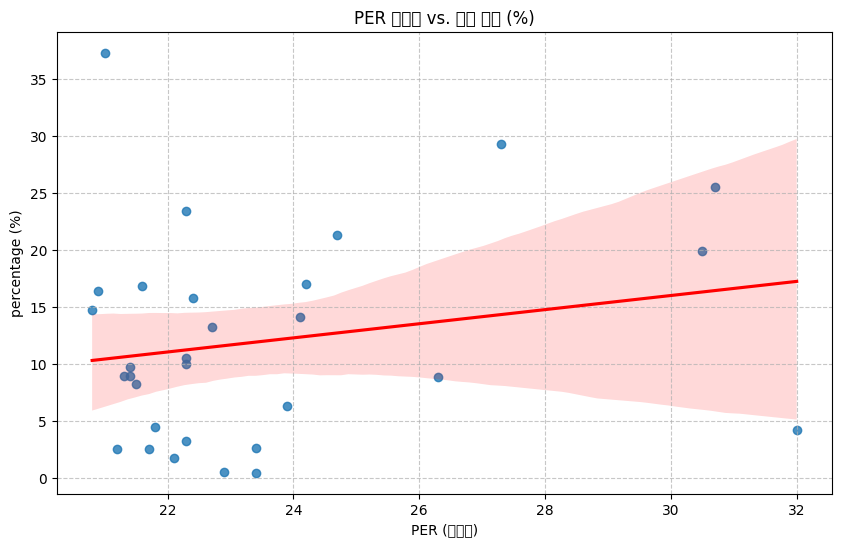

In [70]:
# 플롯 생성
plt.figure(figsize=(10, 6))
sns.regplot(x='PER', y='Percentage_Error_PER', data=comparison_df, scatter_kws={'alpha':0.8}, line_kws={'color': 'red'})

plt.title('PER 실제값 vs. 상대 오차 (%)')
plt.xlabel('PER (실제값)')
plt.ylabel('percentage (%)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()